# Proyecto I: Clasificación y Regresión Lineal

**Contenido:**

- Ejercicio 1: Clasificación lineal (dataset sintético)

## Ejercicio 1 — Clasificación lineal: Dataset de prueba

Generaremos un dataset con dos clases normalmente distribuidas con media total igual a cero. Luego implementaremos:

1. Clasificador con `LogisticRegression` de scikit-learn.
2. Clasificador 'personalizado' usando la función logística con `theta` = promedio de los datos de la clase 1.

Mostraremos las regiones de decisión y compararemos desempeño.

Media global de los datos (debe ser cercana a 0): [ 0.02108896 -0.01265247]
Accuracy (sklearn LogisticRegression) en el dataset de entrenamiento: 0.945
Accuracy (clasificador personalizado con theta = media clase 1): 0.9466666666666667

--- Clasificador sklearn ---
 [[284  16]
 [ 17 283]]
              precision    recall  f1-score   support

         0.0     0.9435    0.9467    0.9451       300
         1.0     0.9465    0.9433    0.9449       300

    accuracy                         0.9450       600
   macro avg     0.9450    0.9450    0.9450       600
weighted avg     0.9450    0.9450    0.9450       600


--- Clasificador personalizado ---
 [[287  13]
 [ 19 281]]
              precision    recall  f1-score   support

         0.0     0.9379    0.9567    0.9472       300
         1.0     0.9558    0.9367    0.9461       300

    accuracy                         0.9467       600
   macro avg     0.9468    0.9467    0.9467       600
weighted avg     0.9468    0.9467    0.9467       6

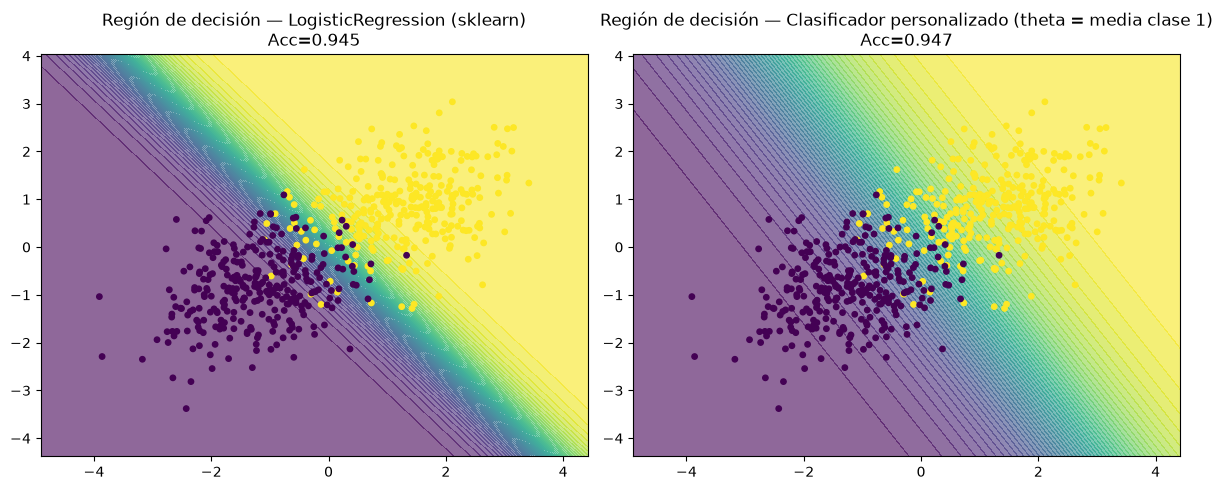

In [13]:

# Ejercicio 1: generación de dataset, entrenamiento y visualización
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

np.random.seed(0)
N = 300  # por clase
mean_shift = np.array([1.2, 0.8])
# clases con medias simétricas: así la media total es cero
mean1 = mean_shift
mean2 = -mean_shift
cov = np.array([[0.8, 0.2],[0.2, 0.6]])  # covarianza
X1 = np.random.multivariate_normal(mean1, cov, size=N)
X2 = np.random.multivariate_normal(mean2, cov, size=N)
X = np.vstack([X1, X2])
y = np.hstack([np.ones(N), np.zeros(N)])

# comprobar media global ~ 0
global_mean = X.mean(axis=0)
print("Media global de los datos (debe ser cercana a 0):", global_mean)

# Entrenamiento con scikit-learn
clf = LogisticRegression(solver='lbfgs')
clf.fit(X, y)
y_pred = clf.predict(X)
acc_sklearn = accuracy_score(y, y_pred)
print("Accuracy (sklearn LogisticRegression) en el dataset de entrenamiento:", acc_sklearn)

# Clasificador personalizado: theta = promedio de los datos de la clase 1
theta = X1.mean(axis=0)  # vector theta de longitud 2
def sigmoid(z):
    return 1/(1+np.exp(-z))

# calculamos probabilidades p = sigmoid(X @ theta)
p_custom = sigmoid(X.dot(theta))
y_pred_custom = (p_custom > 0.5).astype(int)
acc_custom = accuracy_score(y, y_pred_custom)
print("Accuracy (clasificador personalizado con theta = media clase 1):", acc_custom)

# Matriz de confusión y reporte
print("\n--- Clasificador sklearn ---\n", confusion_matrix(y, y_pred))
print(classification_report(y, y_pred, digits=4))
print("\n--- Clasificador personalizado ---\n", confusion_matrix(y, y_pred_custom))
print(classification_report(y, y_pred_custom, digits=4))

# Visualización de datos y regiones de decisión
xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 400),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

Z_sklearn = clf.predict_proba(grid)[:,1].reshape(xx.shape)
Z_custom = sigmoid(grid.dot(theta)).reshape(xx.shape)

fig, axs = plt.subplots(1,2, figsize=(12,5))
# sklearn
axs[0].contourf(xx, yy, Z_sklearn, levels=50, alpha=0.6)
axs[0].scatter(X[:,0], X[:,1], c=y, s=15)
axs[0].set_title("Región de decisión — LogisticRegression (sklearn)\nAcc={:.3f}".format(acc_sklearn))
# personalizado
axs[1].contourf(xx, yy, Z_custom, levels=50, alpha=0.6)
axs[1].scatter(X[:,0], X[:,1], c=y, s=15)
axs[1].set_title("Región de decisión — Clasificador personalizado (theta = media clase 1)\nAcc={:.3f}".format(acc_custom))
plt.tight_layout()
plt.show()
